# H2 Initial Findings: Food Supply and Food Insecurity by Gender

**H2.** Across countries and three-year periods, lower national per-capita calorie and protein supplies are expected to be associated with a higher prevalence of moderate or severe food insecurity among adults, after accounting for income group and period. These associations are expected to be stronger for women than for men.

This notebook covers the first stage of the H2 analysis. We clean and combine three data sources into one country-period table, record which observations are lost at each step, and describe food insecurity and food supply by income group and gender. The regression models that formally test H2 are left for the next stage.

## 1. Data sources and study periods

We use three sources:

- **FAOSTAT Suite of Food Security Indicators**: prevalence of moderate or severe food insecurity among adult women and adult men, reported as three-year averages.
- **FAOSTAT Food Balance Sheets**: annual national calorie and protein supply per person per day.
- **World Bank historical income classifications** (`OGHIST`): the income group of each country in each World Bank fiscal year.

The food security file contains three-year windows from 2000-2002 onward, but the two gender-specific indicators start with 2014-2016. We use three non-overlapping periods, 2014-2016, 2017-2019 and 2020-2022, so that each calendar year enters the analysis only once. Our food balance sheet download ends in 2023, so the next complete window (2023-2025) cannot be matched with supply data.

To run the notebook, set `project_directory` to the folder that contains the extracted FAOSTAT folders and the World Bank workbook.

In [15]:
from pathlib import Path
import pandas
from matplotlib import pyplot

# Folder that contains the extracted FAOSTAT folders and the World Bank workbook.
project_directory = Path.cwd()
project_food_security_file = project_directory / "Food_Security_Data_E_All_Data" / "Food_Security_Data_E_All_Data.csv"
project_food_balance_file = project_directory / "FoodBalanceSheets_E_All_Data" / "FoodBalanceSheets_E_All_Data.csv"
project_income_file = project_directory / "OGHIST_2026_10_08 (1).xlsx"

# Stop with a clear message if a source file is missing.
for project_source_file in [project_food_security_file, project_food_balance_file, project_income_file]:
    if not project_source_file.is_file():
        raise FileNotFoundError(f"Check project_directory and the file name: {project_source_file}")

# The same three non-overlapping periods are used for every data source.
project_years_by_period = {
    "2014-2016": [2014, 2015, 2016],
    "2017-2019": [2017, 2018, 2019],
    "2020-2022": [2020, 2021, 2022]
}

# Item codes contain letters, so they are read as text.
# The income workbook's header is on Excel row 5, and ".." marks a year without a classification.
project_food_security_data = pandas.read_csv(project_food_security_file, dtype={"Item Code": str}, low_memory=False)
project_food_balance_data = pandas.read_csv(project_food_balance_file, dtype={"Item Code": str}, low_memory=False)
project_income_classification_data = pandas.read_excel(
    project_income_file, sheet_name="Country Analytical History", header=4, na_values=[".."]
)

## 2. Female and male food insecurity prevalence

We keep two indicators: the prevalence of moderate or severe food insecurity in the adult female population (`210091F`) and in the adult male population (`210091M`). Both are three-year averages measured in percent, and we use their point estimates (element `Value`).

FAOSTAT gives regional aggregates area codes of 1000 or more. Two aggregates have smaller codes: 351 (China, which combines mainland China, Hong Kong, Macao and Taiwan) and 420 (Sub-Saharan Africa). We drop all aggregates so that only individual countries and economies remain.

The three period columns are stacked with `melt`, and `pivot` then places the female and male estimates side by side. Each row of the result is one country in one period.

In [25]:
# Keep the two gender-specific indicators for individual countries only.
prevalence_source = project_food_security_data[
    project_food_security_data["Item Code"].isin(["210091F", "210091M"])
    & (project_food_security_data["Element"] == "Value")
    & (project_food_security_data["Area Code"] < 1000)
    & ~project_food_security_data["Area Code"].isin([351, 420])
].copy()

# Match each three-year column, such as Y20142016, to its period label.
period_by_prevalence_column = {}
for period_name, period_years in project_years_by_period.items():
    period_by_prevalence_column[f"Y{period_years[0]}{period_years[-1]}"] = period_name

# Stack the three period columns into one column.
prevalence_long = prevalence_source.melt(
    id_vars=["Area Code", "Area", "Item Code"],
    value_vars=list(period_by_prevalence_column),
    var_name="prevalence_period_column",
    value_name="prevalence_percent"
)
prevalence_long["period"] = prevalence_long["prevalence_period_column"].map(period_by_prevalence_column)
prevalence_long["prevalence_percent"] = pandas.to_numeric(prevalence_long["prevalence_percent"])

# Place the female and male estimates on the same country-period row.
prevalence_by_country_period = prevalence_long.pivot(
    index=["Area Code", "Area", "period"],
    columns="Item Code",
    values="prevalence_percent"
).reset_index().rename(columns={
    "Area Code": "country_code",
    "Area": "country_name",
    "210091F": "female_food_insecurity_percent",
    "210091M": "male_food_insecurity_percent"
})
prevalence_by_country_period.columns.name = None

# Country-periods with both estimates are the starting point of the sample.
has_both_estimates = (
    prevalence_by_country_period["female_food_insecurity_percent"].notna()
    & prevalence_by_country_period["male_food_insecurity_percent"].notna()
)
print("Country-periods with both female and male estimates:")
print(prevalence_by_country_period[has_both_estimates].groupby("period").size().to_string())
print()
print(prevalence_by_country_period.head(6).to_string(index=False))

Country-periods with both female and male estimates:
period
2014-2016     99
2017-2019    121
2020-2022    146

 country_code country_name    period  female_food_insecurity_percent  male_food_insecurity_percent
            1      Armenia 2014-2016                             NaN                           NaN
            1      Armenia 2017-2019                            16.3                          13.3
            1      Armenia 2020-2022                             8.8                           7.3
            2  Afghanistan 2014-2016                            47.7                          42.6
            2  Afghanistan 2017-2019                            62.8                          52.4
            2  Afghanistan 2020-2022                            85.5                          72.8


## 3. Calorie and protein supply for the same periods

From the food balance sheets we keep the `Grand Total` rows for two elements: `664`, food supply in kilocalories per person per day, and `674`, protein supply in grams per person per day. Both are national averages, so women and men in the same country share the same values.

The annual values are averaged over the three years of each period, separately for each country and indicator. A period mean is kept only when all three years are available.

In [24]:
# Keep national calorie and protein supply for the countries in the prevalence table.
supply_source = project_food_balance_data[
    (project_food_balance_data["Item"] == "Grand Total")
    & project_food_balance_data["Element Code"].isin([664, 674])
    & project_food_balance_data["Area Code"].isin(prevalence_source["Area Code"])
].copy()

# Match each annual column, such as Y2014, to its period label.
period_by_annual_column = {}
for period_name, period_years in project_years_by_period.items():
    for calendar_year in period_years:
        period_by_annual_column[f"Y{calendar_year}"] = period_name

# Stack the nine annual columns while keeping the country and the supply indicator.
annual_supply = supply_source.melt(
    id_vars=["Area Code", "Element Code"],
    value_vars=list(period_by_annual_column),
    var_name="annual_column",
    value_name="annual_supply"
).rename(columns={"Area Code": "country_code"})
annual_supply["period"] = annual_supply["annual_column"].map(period_by_annual_column)
annual_supply["annual_supply"] = pandas.to_numeric(annual_supply["annual_supply"])
annual_supply["supply_variable"] = annual_supply["Element Code"].map({
    664: "calorie_supply_kilocalories_per_person_per_day",
    674: "protein_supply_grams_per_person_per_day"
})

# Average each indicator over its three years and keep only complete periods.
supply_averages = annual_supply.groupby(
    ["country_code", "period", "supply_variable"], as_index=False
).agg(
    years_with_supply_data=("annual_supply", "count"),
    three_year_average_supply=("annual_supply", "mean")
)
supply_averages = supply_averages[supply_averages["years_with_supply_data"] == 3].copy()

# Give calorie and protein supply their own columns.
supplies_by_country_period = supply_averages.pivot(
    index=["country_code", "period"],
    columns="supply_variable",
    values="three_year_average_supply"
).reset_index()
supplies_by_country_period.columns.name = None
print(supplies_by_country_period.head(6).round(2).to_string(index=False))

 country_code    period  calorie_supply_kilocalories_per_person_per_day  protein_supply_grams_per_person_per_day
            1 2014-2016                                         3158.78                                   106.72
            1 2017-2019                                         3099.34                                   104.50
            1 2020-2022                                         3133.01                                   104.86
            2 2014-2016                                         2254.14                                    64.77
            2 2017-2019                                         2264.03                                    63.00
            2 2020-2022                                         2257.77                                    62.04


## 4. Historical income groups

Each period takes the World Bank classification based on income data for its middle year. The FY17, FY20 and FY23 classifications use income data for 2015, 2018 and 2021 and took effect in July 2016, July 2019 and July 2022.

The World Bank and FAOSTAT spell some country names differently. We rename the World Bank versions to the FAOSTAT names, then reshape the three fiscal-year columns into country-period rows.

In [23]:
# Match each fiscal-year column to the period whose middle year it is based on.
period_by_income_column = {
    "FY17": "2014-2016",
    "FY20": "2017-2019",
    "FY23": "2020-2022"
}

# Drop explanatory rows without a country code, then keep country names and the three income columns.
income_source = project_income_classification_data.dropna(
    subset=[project_income_classification_data.columns[0]]
).rename(columns={
    project_income_classification_data.columns[1]: "country_name"
})[["country_name", "FY17", "FY20", "FY23"]].copy()

# World Bank names that differ from the FAOSTAT names.
country_name_replacements = {
    "Bahamas, The": "Bahamas",
    "Bolivia": "Bolivia (Plurinational State of)",
    "Congo, Dem. Rep.": "Democratic Republic of the Congo",
    "Egypt, Arab Rep.": "Egypt",
    "Gambia, The": "Gambia",
    "Iran, Islamic Rep.": "Iran (Islamic Republic of)",
    "Kyrgyz Republic": "Kyrgyzstan",
    "Lao PDR": "Lao People's Democratic Republic",
    "Naoero": "Nauru",
    "Netherlands": "Netherlands (Kingdom of the)",
    "West Bank and Gaza": "Palestine",
    "Korea, Rep.": "Republic of Korea",
    "Moldova": "Republic of Moldova",
    "St. Lucia": "Saint Lucia",
    "St. Vincent and the Grenadines": "Saint Vincent and the Grenadines",
    "São Tomé and Príncipe": "Sao Tome and Principe",
    "Slovak Republic": "Slovakia",
    "Tanzania": "United Republic of Tanzania",
    "United Kingdom": "United Kingdom of Great Britain and Northern Ireland",
    "United States": "United States of America",
    "Yemen, Rep.": "Yemen"
}
income_source["country_name"] = (
    income_source["country_name"].str.strip().replace(country_name_replacements)
)

# Stack the three fiscal-year columns and attach the period labels.
income_by_country_period = income_source.melt(
    id_vars=["country_name"],
    value_vars=list(period_by_income_column),
    var_name="income_year_column",
    value_name="income_group_code"
)
income_by_country_period["period"] = income_by_country_period["income_year_column"].map(period_by_income_column)
income_by_country_period["income_group"] = income_by_country_period["income_group_code"].map({
    "L": "Low income",
    "LM": "Lower-middle income",
    "UM": "Upper-middle income",
    "H": "High income"
})
print(income_by_country_period.head(6).to_string(index=False))

  country_name income_year_column income_group_code    period        income_group
   Afghanistan               FY17                 L 2014-2016          Low income
       Albania               FY17                UM 2014-2016 Upper-middle income
       Algeria               FY17                UM 2014-2016 Upper-middle income
American Samoa               FY17                UM 2014-2016 Upper-middle income
       Andorra               FY17                 H 2014-2016         High income
        Angola               FY17                UM 2014-2016 Upper-middle income


## 5. Combined country-period table and sample flow

Prevalence and supply are joined on the FAO area code and period, and income groups are joined on the standardized country name and period. A country-period is kept only when it has both gender estimates, both supply means and an income group, so every summary below uses the same sample.

The first table below counts the country-periods lost at each step. The second lists the countries that were dropped.

In [22]:
# Join prevalence with both supply indicators.
matched_data = prevalence_by_country_period.merge(
    supplies_by_country_period[[
        "country_code", "period",
        "calorie_supply_kilocalories_per_person_per_day",
        "protein_supply_grams_per_person_per_day"
    ]],
    on=["country_code", "period"],
    how="left",
    validate="one_to_one"
)

# Join the income group by standardized country name and period.
matched_data = matched_data.merge(
    income_by_country_period[["country_name", "period", "income_group"]],
    on=["country_name", "period"],
    how="left",
    validate="many_to_one"
)

# Start from country-periods with both gender estimates and flag the missing pieces.
with_both_estimates = matched_data[
    matched_data["female_food_insecurity_percent"].notna()
    & matched_data["male_food_insecurity_percent"].notna()
].copy()
with_both_estimates["missing_supply"] = (
    with_both_estimates["calorie_supply_kilocalories_per_person_per_day"].isna()
    | with_both_estimates["protein_supply_grams_per_person_per_day"].isna()
)
with_both_estimates["missing_income_group"] = (
    with_both_estimates["income_group"].isna() & ~with_both_estimates["missing_supply"]
)
with_both_estimates["retained"] = (
    ~with_both_estimates["missing_supply"] & ~with_both_estimates["missing_income_group"]
)

# Count the country-periods at each step.
sample_flow = with_both_estimates.groupby("period").agg(
    with_both_gender_estimates=("country_code", "count"),
    dropped_no_supply_data=("missing_supply", "sum"),
    dropped_no_income_group=("missing_income_group", "sum"),
    retained=("retained", "sum")
)
sample_flow.loc["Total"] = sample_flow.sum()
print(sample_flow.to_string())

# List the dropped countries and check whether they appear anywhere in the food balance sheets.
dropped_records = with_both_estimates[~with_both_estimates["retained"]].copy()
dropped_records["in_food_balance_sheets"] = dropped_records["country_code"].isin(
    project_food_balance_data["Area Code"]
)
dropped_countries = dropped_records.groupby("country_name").agg(
    income_group=("income_group", lambda groups: ", ".join(groups.dropna().unique())),
    periods_dropped=("period", ", ".join),
    in_food_balance_sheets=("in_food_balance_sheets", "any")
).sort_values("income_group")
print("\nDropped countries:")
print(dropped_countries.to_string())

# The analysis table: one row per country and period with complete information.
country_period_data = with_both_estimates[with_both_estimates["retained"]][[
    "country_code", "country_name", "period", "income_group",
    "calorie_supply_kilocalories_per_person_per_day",
    "protein_supply_grams_per_person_per_day",
    "female_food_insecurity_percent", "male_food_insecurity_percent"
]].sort_values(["country_code", "period"]).reset_index(drop=True)

periods_per_country = country_period_data.groupby("country_code")["period"].count()
print("\nCountry-period observations:", len(country_period_data))
print("Distinct countries or economies:", country_period_data["country_code"].nunique())
print("Countries present in all three periods:", (periods_per_country == 3).sum())

           with_both_gender_estimates  dropped_no_supply_data  dropped_no_income_group  retained
period                                                                                          
2014-2016                          99                       5                        0        94
2017-2019                         121                       8                        0       113
2020-2022                         146                      10                        0       136
Total                             366                      23                        0       343

Dropped countries:
                                             income_group                  periods_dropped  in_food_balance_sheets
country_name                                                                                                      
Japan                                         High income  2014-2016, 2017-2019, 2020-2022                   False
Singapore                                     High in

## 6. Food insecurity by income group and gender

For each period and income group we report the number of countries, the mean female and male prevalence, the mean gap (female minus male, in percentage points) and the number of countries in which the female estimate is higher. Each country has equal weight within its group.

In [20]:
# Female-minus-male gap for each country-period, in percentage points.
country_period_data["female_minus_male_points"] = (
    country_period_data["female_food_insecurity_percent"]
    - country_period_data["male_food_insecurity_percent"]
)
country_period_data["female_higher"] = country_period_data["female_minus_male_points"] > 0

income_summary = country_period_data.groupby(["period", "income_group"], as_index=False).agg(
    country_count=("country_code", "count"),
    female_mean_percent=("female_food_insecurity_percent", "mean"),
    male_mean_percent=("male_food_insecurity_percent", "mean"),
    mean_gap_points=("female_minus_male_points", "mean"),
    countries_female_higher=("female_higher", "sum")
)

# Order the income groups from low to high in every table and chart.
income_group_order = ["Low income", "Lower-middle income", "Upper-middle income", "High income"]
income_summary["income_group_rank"] = income_summary["income_group"].map(
    {income_group_name: rank for rank, income_group_name in enumerate(income_group_order)}
)
income_summary = income_summary.sort_values(["period", "income_group_rank"]).drop(
    columns="income_group_rank"
).reset_index(drop=True)

print(income_summary.rename(columns={
    "period": "Period", "income_group": "Income group", "country_count": "Countries",
    "female_mean_percent": "Female mean (%)", "male_mean_percent": "Male mean (%)",
    "mean_gap_points": "Mean gap (pts)", "countries_female_higher": "Female higher"
}).round(2).to_string(index=False))

# Direction of the gap across all country-periods.
gap = country_period_data["female_minus_male_points"]
print("\nAll country-periods:", len(gap))
print("  Female estimate higher:", (gap > 0).sum())
print("  Equal estimates:       ", (gap == 0).sum())
print("  Male estimate higher:  ", (gap < 0).sum())

   Period        Income group  Countries  Female mean (%)  Male mean (%)  Mean gap (pts)  Female higher
2014-2016          Low income         10            58.82          57.89            0.93              8
2014-2016 Lower-middle income         21            32.95          29.67            3.28             14
2014-2016 Upper-middle income         28            25.46          22.24            3.22             25
2014-2016         High income         35             9.23           7.75            1.49             30
2017-2019          Low income         14            56.18          55.28            0.90              6
2017-2019 Lower-middle income         27            36.76          35.04            1.72             14
2017-2019 Upper-middle income         37            25.52          22.55            2.97             27
2017-2019         High income         35             8.33           7.15            1.19             26
2020-2022          Low income         14            66.76       

## 7. Chart: mean prevalence by income group and gender

The three panels share one vertical scale, so the levels can be compared across income groups. Because the set of countries changes from one period to the next, differences between panels mix real change with changes in sample composition.

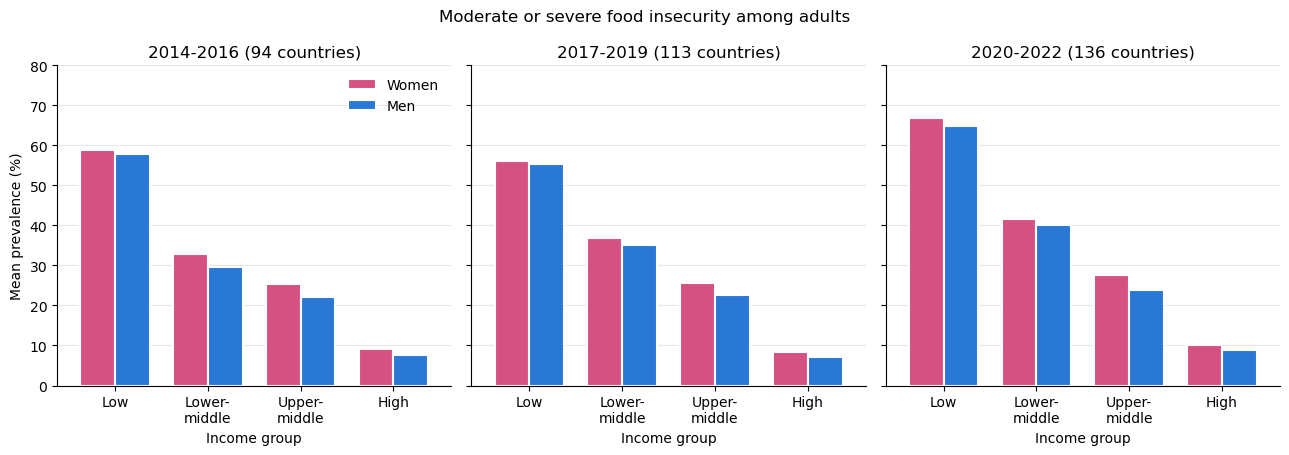

In [19]:
# Colors for women and men, in the same order as the y columns below (Women, then Men).
gender_colors = ["#d55181", "#2a78d6"]

# Shorter income-group labels for the x-axis. "\n" splits a long label over two lines.
short_income_labels = {
    "Low income": "Low",
    "Lower-middle income": "Lower-\nmiddle",
    "Upper-middle income": "Upper-\nmiddle",
    "High income": "High"
}

# Create one figure with three panels side by side, one for each period.
# sharey=True gives the three panels the same vertical scale, so their bars can be compared.
prevalence_figure, prevalence_axes = pyplot.subplots(1, 3, figsize=(13, 4.6), sharey=True)

# zip pairs the first panel with the first period, the second panel with the second period, and so on.
for axis, period_name in zip(prevalence_axes, project_years_by_period):
    # Keep this period's four income groups. The new column names become the legend labels.
    plot_data = income_summary[income_summary["period"] == period_name].rename(columns={
        "female_mean_percent": "Women", "male_mean_percent": "Men"
    })
    plot_data["income_label"] = plot_data["income_group"].map(short_income_labels)

    # Draw a women's bar and a men's bar for each income group in the current panel (ax=axis).
    # The white edge leaves a thin gap between neighbouring bars. The legend is added once, after the loop.
    plot_data.plot(
        x="income_label", y=["Women", "Men"], kind="bar", ax=axis, rot=0,
        color=gender_colors, width=0.75, edgecolor="white", linewidth=1.5, legend=False
    )

    # The panel title shows the period and its number of countries (the sum over the four groups).
    axis.set_title(f"{period_name} ({plot_data['country_count'].sum()} countries)")
    axis.set_xlabel("Income group")
    # The highest group mean is below 70%, so a 0-80% scale keeps the bars easy to read.
    axis.set_ylim(0, 80)
    # Draw light horizontal grid lines behind the bars and remove the top and right borders.
    axis.grid(axis="y", color="#e6e6e6")
    axis.set_axisbelow(True)
    axis.spines[["top", "right"]].set_visible(False)

# The panels share the y-axis, so the axis label and the legend only go on the first panel.
prevalence_axes[0].set_ylabel("Mean prevalence (%)")
prevalence_axes[0].legend(frameon=False)
prevalence_figure.suptitle("Moderate or severe food insecurity among adults")
# Adjust the spacing so that titles and labels do not overlap.
prevalence_figure.tight_layout()

## 8. Calorie and protein supply by income group

The table pools the three periods, so a country can contribute up to three rows. It shows the level and the range of each supply measure within each income group.

In [18]:
# Short names for the two supply columns. Sections 9 and 10 use them as well.
calorie_column = "calorie_supply_kilocalories_per_person_per_day"
protein_column = "protein_supply_grams_per_person_per_day"

# Group by income group only, so the three periods are pooled together.
# rows_in_three_periods counts rows, so a country that stays in the same group is counted up to three times.
# The mean, minimum and maximum describe the level and the range of each supply measure in the group.
# reindex lists the groups from low to high income instead of in alphabetical order.
supply_summary = country_period_data.groupby("income_group").agg(
    rows_in_three_periods=("country_code", "count"),
    calories_mean=(calorie_column, "mean"),
    calories_min=(calorie_column, "min"),
    calories_max=(calorie_column, "max"),
    protein_mean=(protein_column, "mean"),
    protein_min=(protein_column, "min"),
    protein_max=(protein_column, "max")
).reindex(income_group_order)

# Round only when printing, so the stored values keep their full precision.
print("Calories in kcal/person/day; protein in g/person/day.\n")
print(supply_summary.round(1).to_string())

# Overall means across all country-periods, for comparison with the group means.
print("\nAll country-periods: mean calories", round(country_period_data[calorie_column].mean(), 1),
      "| mean protein", round(country_period_data[protein_column].mean(), 1))

Calories in kcal/person/day; protein in g/person/day.

                     rows_in_three_periods  calories_mean  calories_min  calories_max  protein_mean  protein_min  protein_max
income_group                                                                                                                 
Low income                              38         2374.7        1878.0        2862.8          61.5         28.4         92.6
Lower-middle income                     90         2709.6        1812.4        3508.9          74.2         47.0        129.9
Upper-middle income                    103         3039.4        2445.1        3808.1          92.8         64.3        132.6
High income                            112         3393.6        2466.7        3948.4         111.4         76.4        152.4

All country-periods: mean calories 2994.9 | mean protein 90.5


## 9. Lower and higher food supply within income groups

Food supply rises with income (Section 8), so a comparison across all countries would mostly show income differences. We therefore compare countries only with others in the same period and income group.

In each of the 12 period-income groups, countries below the group's median supply form the **lower-supply half**, and the remaining countries form the **higher-supply half**. When a group has an odd number of countries, the higher half has one more. We then subtract the higher half's mean prevalence from the lower half's, separately for women and men, and do this once for calories and once for protein.

A positive difference, in percentage points, means that the countries with less food supply have more food insecurity. If H2 holds, the differences should be positive and larger for women than for men.

In [16]:
# The two supply measures compared in this section.
supply_measures = {"Calories": calorie_column, "Protein": protein_column}

# Start from the number of countries in each period and income group.
# income_summary is already sorted from low to high income, so the result keeps that order.
supply_comparison = income_summary[["period", "income_group", "country_count"]].copy()

# Work on a copy so that the helper columns below are not added to country_period_data.
comparison_data = country_period_data.copy()

for supply_name, supply_column in supply_measures.items():
    # transform("median") writes each period-income group's median supply on every row of that group.
    comparison_data["group_median"] = comparison_data.groupby(
        ["period", "income_group"]
    )[supply_column].transform("median")

    # Countries below their group's median are labelled "Lower"; all other countries are "Higher".
    comparison_data["supply_half"] = "Higher"
    below_median = comparison_data[supply_column] < comparison_data["group_median"]
    comparison_data.loc[below_median, "supply_half"] = "Lower"

    # Mean female and male prevalence in each half, with every country weighted equally.
    half_means = comparison_data.groupby(["period", "income_group", "supply_half"], as_index=False).agg(
        female_mean=("female_food_insecurity_percent", "mean"),
        male_mean=("male_food_insecurity_percent", "mean")
    )

    # Place the lower and higher halves of each group on the same row.
    lower_half = half_means[half_means["supply_half"] == "Lower"].drop(columns="supply_half")
    higher_half = half_means[half_means["supply_half"] == "Higher"].drop(columns="supply_half")
    both_halves = lower_half.merge(higher_half, on=["period", "income_group"], suffixes=("_lower", "_higher"))

    # Difference = lower half minus higher half, in percentage points.
    both_halves[f"{supply_name}: women"] = both_halves["female_mean_lower"] - both_halves["female_mean_higher"]
    both_halves[f"{supply_name}: men"] = both_halves["male_mean_lower"] - both_halves["male_mean_higher"]
    supply_comparison = supply_comparison.merge(
        both_halves[["period", "income_group", f"{supply_name}: women", f"{supply_name}: men"]],
        on=["period", "income_group"],
        how="left"
    )

print("Lower-supply half minus higher-supply half, mean prevalence in percentage points.\n")
print(supply_comparison.rename(columns={
    "period": "Period", "income_group": "Income group", "country_count": "Countries"
}).round(1).to_string(index=False))

# Count the groups where lower supply goes with higher prevalence, and where the women's difference is larger.
group_total = len(supply_comparison)
for supply_name in supply_measures:
    women_difference = supply_comparison[f"{supply_name}: women"]
    men_difference = supply_comparison[f"{supply_name}: men"]
    print(f"\n{supply_name}:")
    print(f"  Lower-supply half has higher prevalence for women in {(women_difference > 0).sum()} of {group_total} groups")
    print(f"  Lower-supply half has higher prevalence for men in {(men_difference > 0).sum()} of {group_total} groups")
    print(f"  Women's difference is larger than men's in {(women_difference > men_difference).sum()} of {group_total} groups")

Lower-supply half minus higher-supply half, mean prevalence in percentage points.

   Period        Income group  Countries  Calories: women  Calories: men  Protein: women  Protein: men
2014-2016          Low income         10             16.7           15.3            18.3          16.7
2014-2016 Lower-middle income         21             11.8            9.9            13.3          12.5
2014-2016 Upper-middle income         28             15.3           14.5            14.7          12.5
2014-2016         High income         35             -0.2           -1.0             0.6          -0.2
2017-2019          Low income         14             13.4            9.4            13.2          12.0
2017-2019 Lower-middle income         27             10.7           12.0            15.7          16.0
2017-2019 Upper-middle income         37             13.6           13.3            13.3          11.6
2017-2019         High income         35              2.9            1.6             1.1     

## 10. Scatter plots of supply and prevalence

Each point is one country in one period. The top row uses calorie supply and the bottom row protein supply; the left column shows women and the right column men. Colors mark income groups, from light (low income) to dark (high income).

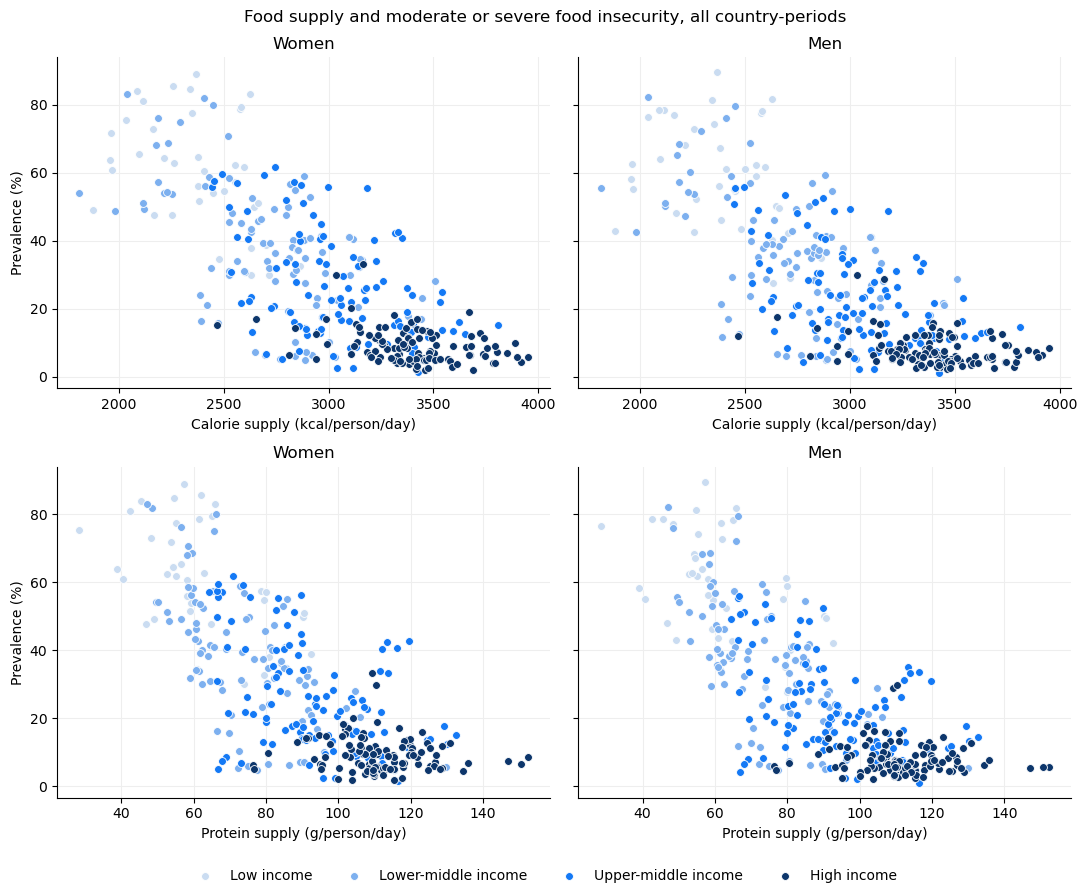

In [27]:
# One shade of blue per income group, from light (low income) to dark (high income).
income_group_colors = {
    "Low income": "#cadcf1",
    "Lower-middle income": "#7db0ef",
    "Upper-middle income": "#1479f5",
    "High income": "#0d366b"
}

# Axis labels for the two supply measures and panel titles for the two genders, keyed by column name.
supply_labels = {
    calorie_column: "Calorie supply (kcal/person/day)",
    protein_column: "Protein supply (g/person/day)"
}
gender_labels = {
    "female_food_insecurity_percent": "Women",
    "male_food_insecurity_percent": "Men"
}

# Create a 2 x 2 grid: the rows are the two supply measures and the columns are women and men.
# sharex="row" gives the two panels in a row the same x-axis; sharey=True gives all four panels the same y-axis.
scatter_figure, scatter_axes = pyplot.subplots(2, 2, figsize=(11, 9), sharex="row", sharey=True)

# enumerate supplies the row and column numbers used to select each panel.
for row_number, (supply_column, supply_label) in enumerate(supply_labels.items()):
    for column_number, (prevalence_column, gender_label) in enumerate(gender_labels.items()):
        axis = scatter_axes[row_number, column_number]

        # Plot each income group separately so that it gets its own color and legend entry.
        # Each point is one country in one period.
        for income_group_name, group_color in income_group_colors.items():
            group_data = country_period_data[country_period_data["income_group"] == income_group_name]
            axis.scatter(
                group_data[supply_column], group_data[prevalence_column],
                s=32, color=group_color, edgecolor="white", linewidth=0.6, label=income_group_name
            )
        axis.set_title(gender_label)
        axis.set_xlabel(supply_label)
        # Draw a light grid behind the points and remove the top and right borders.
        axis.grid(color="#eeeeee")
        axis.set_axisbelow(True)
        axis.spines[["top", "right"]].set_visible(False)

    # All panels share the y-axis, so only the left panel of each row needs a y-axis label.
    scatter_axes[row_number, 0].set_ylabel("Prevalence (%)")

# Every panel uses the same colors, so one legend below the grid is enough.
# Its entries are taken from the first panel.
legend_handles, legend_labels = scatter_axes[0, 0].get_legend_handles_labels()
scatter_figure.legend(legend_handles, legend_labels, loc="lower center", ncol=4, frameon=False)
scatter_figure.suptitle("Food supply and moderate or severe food insecurity, all country-periods")
# rect reserves the bottom 4% of the figure for the shared legend.
scatter_figure.tight_layout(rect=(0, 0.04, 1, 1))

## Initial findings

**Sample.** 366 country-periods have both a female and a male estimate. Of these, 23 are dropped because the food balance sheets contain no records for the country, and none are lost when income groups are matched. The final table has **343 country-period observations from 141 countries or economies**, and 91 countries appear in all three periods. The losses fall mostly on the low-income group: 13 of its 51 country-periods (about one in four) are dropped, including Chad, Togo, Mali and South Sudan. Results for this group therefore rest on only 10 to 14 countries per period.

**Food insecurity by income group.** In every period, mean prevalence is lower in each higher income group. In 2020-2022 it is **66.76% for women and 64.94% for men** in the low-income group, compared with **10.15% and 8.79%** in the high-income group.

**Women and men.** The female mean is higher than the male mean in all 12 period-income groups, but the gaps are small, between 0.90 and 3.77 percentage points. They are largest in the upper-middle-income group (2.97 to 3.77 points) and smallest in the low-income group (0.90 to 1.82 points). At the country level the pattern is less uniform. The female estimate is higher in 238 of the 343 country-periods, equal in 26 and lower in 79. In the low-income group, women have the higher estimate in only 20 of 38 country-periods.

**Food supply.** Average supply rises with income, from 2,374.7 kcal and 61.5 g of protein per person per day in the low-income group to 3,393.6 kcal and 111.4 g in the high-income group. The ranges of neighbouring groups overlap considerably, so supply also varies within each income group.

**Supply and food insecurity.** Within the same period and income group, countries with less food supply generally have more food insecurity. For calories, the lower-supply half has the higher mean prevalence in 11 of the 12 groups, for women and for men alike. For protein, it does so in all 12 groups for women and in 10 of 12 for men. Outside the high-income group the differences are large, mostly between 9 and 25 percentage points. The one exception is protein in the 2020-2022 low-income group, where the two halves differ by less than one point. In the high-income group, where food insecurity is low, the differences are small, from -1.0 to 5.7 points.

**Stronger for women?** The women's difference is larger than the men's in 11 of 12 groups for calories and in 10 of 12 for protein. The extra amount is small, about 1 percentage point in a typical group (median 1.2 points for calories and 0.9 for protein). The largest are for calories in the low-income group, 4.1 points in 2017-2019 and 5.2 points in 2020-2022. Because women's prevalence is higher to begin with, a slightly larger difference in percentage points may partly reflect that higher level. These results point in the direction H2 expects, but the regression stage is needed to judge whether the difference between women and men is meaningful.

**Limitations.** These are simple comparisons of group means. Each half contains only 5 to 21 countries, so a few countries can change a result, particularly in the low-income group. No factors other than income group and period are held constant. National supply measures how much food is available in a country, not how it is shared within households, so the results do not describe effects on individual women or men.

**Next step.** We will estimate regression models of female and male prevalence on calorie and protein supply with income-group and period effects. A gender-by-supply interaction will test whether the association is stronger for women.